> **How to use this notebook.** Markdown cells contain the paper text, ready to copy. Code cells rebuild every figure
> and table from the experiment results in `backend/reports/realistic_eval/results/`, so each number can be traced to its source.
> Figures are also saved as 300-dpi PNGs in `paper/figures/` for Word/LaTeX. Run with *Run All* (Python ≥3.10, numpy, pandas, matplotlib).
> **Submission version: `paper/overleaf/main.tex`** (upload `paper/SwarSetu_Overleaf.zip` to Overleaf). This notebook has the same text and regenerates the figures/tables; it also keeps two supplementary figures (calibration, handwriting samples) that the 8-page LaTeX version omits.

# SwarSetu: Age- and Language-Normed Joint Screening for Dyslexia, Dyscalculia and Dysgraphia — A Realistic Synthetic Benchmark and a Deployment Audit

**[Author Name]¹, [Co-author Name]¹, [Supervisor Name]²**
¹[Department], [Institution], [City, Country]  ²[Department], [Institution], [City, Country]
Corresponding author: [e-mail]

---

***Abstract*—Specific learning disorders (SLDs) in reading, mathematics and written expression often co-occur and are under-identified where specialists are scarce. We present SwarSetu, a multilingual tablet screen in which every session administers three DSM-5-based tests — reading, mathematics and written expression — and one model per disorder scores the risk of dyslexia, dyscalculia and dysgraphia from the combined profile. We first show that the system's original synthetic benchmark was too easy: plain logistic regression reached AUROC 0.96 because the per-feature effect size was Cohen's *d* ≈ 1.5. We replace it with a liability-threshold cohort generator that models correlated abilities, comorbidity, age and home-language confounds, device effects, missing data and imperfect reference diagnoses. Over five seeds (*n* = 6000) and a distribution-shifted external site, the originally proposed FT-Transformer reaches macro AUROC 0.804, no better than logistic regression (0.807). A LightGBM pipeline on age- and language-normed features reaches 0.858 (95% CI 0.846–0.869) with per-disorder AUROCs of 0.855, 0.853 and 0.859, beats every alternative in paired bootstrap tests, is calibrated (ECE 0.017), gives class-conditional conformal coverage of 0.94/0.90 and stays best, or within 0.005 of best, in all 22 settings of a sensitivity analysis. A device-invariant handwriting analysis corrects a scorer that rated neat touch-screen writing below tremulous writing. We align the screen with DSM-5 Criteria A–D and report an audit that found 17 defects which together made the deployed screen flag no child. All results are synthetic and do not estimate clinical accuracy.**

***Index Terms*—dyslexia, dyscalculia, dysgraphia, early screening, synthetic data, gradient boosting, calibration, conformal prediction, fairness, ML system audit.**

In [1]:
# ---- Setup: paths, palette, helpers (not part of the paper text) ----
import json, os, pathlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import Markdown, display

ROOT = pathlib.Path.cwd()
if not (ROOT / "backend").exists():          # notebook lives in <repo>/paper
    ROOT = ROOT.parent
RES = ROOT / "backend/reports/realistic_eval/results"
OLD_FIGS = ROOT / "backend/reports/realistic_eval/paper/figures"
FIG = ROOT / "paper/figures"; FIG.mkdir(parents=True, exist_ok=True)
load = lambda f: json.load(open(RES / f, encoding="utf-8"))

summary   = load("summary.json")
dynamics  = load("lightgbm_dynamics.json")
sensboot  = load("sensitivity_bootstrap.json")
dsm5      = load("dsm5_evaluation.json")
orf       = load("orf_simulation.json")

# One fixed colour + marker per model in every figure (validated categorical palette, fixed order).
STYLE = {
    "LightGBM pipeline":          ("#2a78d6", "o"),
    "LR + demographics":          ("#eb6834", "s"),
    "Logistic regression":        ("#1baf7a", "^"),
    "Random forest":              ("#eda100", "D"),
    "XGBoost":                    ("#e87ba4", "v"),
    "FT-Transformer (BCE)":       ("#008300", "P"),
    "FT-Transformer (ASL+Dice)":  ("#6250d6", "X"),
    "Deployed FT (as served)":    ("#e34948", "*"),
}
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e4e3dd"
plt.rcParams.update({
    "font.family": "serif", "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "lines.linewidth": 1.6,
    "lines.markersize": 4.5, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
})
COL1, COL2 = 3.5, 7.16   # IEEE single / double column width (inches)

def pm(v, d=3):
    return f"{v[0]:.{d}f} ± {v[1]:.{d}f}"

def show_table(df, caption):
    display(Markdown(f"**{caption}**\n\n" + df.to_markdown(index=False) if hasattr(df, "to_markdown") and _has_tabulate()
                     else f"**{caption}**\n\n" + _md(df)))

def _has_tabulate():
    try:
        import tabulate  # noqa
        return True
    except ImportError:
        return False

def _md(df):
    head = "| " + " | ".join(map(str, df.columns)) + " |\n|" + "---|" * len(df.columns) + "\n"
    return head + "\n".join("| " + " | ".join(map(str, r)) + " |" for r in df.values)

print("Results loaded from", RES)

Results loaded from D:\OneDrive\Desktop\swar-setu-main\backend\reports\realistic_eval\results


## I. Introduction

DSM-5 groups persistent impairments in reading (dyslexia), mathematics (dyscalculia) and written expression (dysgraphia) under a single diagnosis of specific learning disorder, with a school-age prevalence of 5–15% [1]. A quarter to a half of children with one of these disorders also meet the criteria for another [2]. Intervention is most effective in the primary grades, yet formal assessment requires psychologists and special educators who are scarce in many school systems, particularly in multilingual, low-resource settings such as rural India. A short, inexpensive screen that a teacher can administer, and that covers all three disorders, could help decide which children need a specialist first.

SwarSetu is such a screen. Children complete reading, arithmetic and handwriting tasks on a tablet or phone; spoken answers are transcribed, handwriting is analysed, and a model scores the risk of each disorder for teachers and parents in English or Hindi. Its first evaluation reported an AUROC near 0.97 on synthetic data. Before such a tool reaches children we must know whether that evaluation reflects real measurement conditions, which model to deploy, and whether the deployed software computes what was evaluated. This paper makes five contributions:

1. **A realistic synthetic cohort generator** for joint screening of the three disorders, in which comorbidity, confounding and measurement artefacts arise from a liability-threshold model rather than being imposed on labels (Section IV).
2. **A screening pipeline** that norms features for age and home language, uses gradient boosting, pre-registered operating points and class-conditional conformal sets, and ships model, preprocessing and thresholds as one verified bundle (Section V).
3. **An evaluation** of model variants over five seeds and an external site, with paired bootstrap intervals, learning curves and a 22-setting sensitivity analysis of the generator's own assumptions (Sections VII–VIII).
4. **Device-invariant handwriting analysis, self-hosted speech recognition and DSM-5 alignment**, including specifier-level subtests and a teacher questionnaire for Criteria A–D (Section VI).
5. **A deployment audit** with executable checks, distilled into general lessons for ML screening systems (Section IX).

All data are synthetic. The results test the pipeline under plausible conditions; they do not estimate clinical accuracy (Section X).

## II. Related Work

**ML screening for SLDs.** Most machine-learning screens target a single disorder: eye-tracking features during reading for dyslexia [3], and tablet handwriting kinematics for dysgraphia, where Asselborn *et al.* reached human-level classification with a consumer tablet [4]. Few systems screen all three disorders jointly, even though comorbidity is the rule rather than the exception [2], and few report how their tasks behave across ages, languages and input devices.

**Models for tabular data.** On tabular data of moderate size, gradient-boosted decision trees usually match or beat deep networks [5], including the FT-Transformer [6], which tokenises each feature and applies self-attention. Our results confirm this for screening data and show *why* the choice matters less than feature construction.

**Calibration, uncertainty and fairness.** When predicted probabilities drive referral decisions they must be calibrated; temperature scaling is the standard post-hoc fix for neural networks [7]. Split conformal prediction gives distribution-free coverage guarantees, and its class-conditional variant extends the guarantee to each class separately, which matters when the class of interest is rare [8]. We report group false-positive rates at a fixed operating point.

**ML systems engineering.** Production ML systems often fail through pipeline problems such as train/serve skew and configuration debt rather than through the model itself [9]. Our audit (Section IX) is a concrete case study of these failure modes in a health-adjacent application.

## III. System Overview

SwarSetu is a React/TypeScript web application with a Python (Flask) backend and a PostgreSQL (Supabase) store. Teachers register a class, complete a short profile for each child, and run one or more tests; parents see progress and practice activities. Fig. 1 shows the screening path.

**Tasks and features.** Four extractors map task telemetry to 16 features each (64 in total), scaled to [0, 1] with higher values meaning better performance: (i) *reading* — speed, accuracy, phoneme errors, letter confusions, pseudoword decoding, rapid automatised naming, phonological awareness, comprehension and oral reading fluency; (ii) *mathematics* — subitising, magnitude comparison, fact retrieval, number line, place value, multi-step accuracy and word problems; (iii) *handwriting* — legibility, fluency, motor control and layout (Section VI); (iv) *behaviour* — attention, persistence, impulse control and related executive measures recorded during the session.

**Screening protocol.** Every screening session administers all three tests in a fixed order (reading, mathematics, written expression), and the three are scored together by the comprehensive model. Because a quarter to a half of affected children have more than one disorder [2], screening one domain alone risks missing a co-occurring one. A single test is run only when the teacher explicitly permits it — for example a follow-up re-screen of one domain, or a child unable to finish the session — and records a reason that is stored with the result; it is then scored by a single-test model. The backend refuses to produce a comprehensive result from an incomplete battery.

**Originally proposed model.** The first version used an FT-Transformer-style network [6] (1.06 M parameters) with four 16-feature domain tokens, a learnable label-correlation layer, an asymmetric loss (ASL) [10] plus a Dice term, Monte-Carlo dropout and temperature scaling [7]. When a child took only one test, the other 48 features were filled with 0.5.

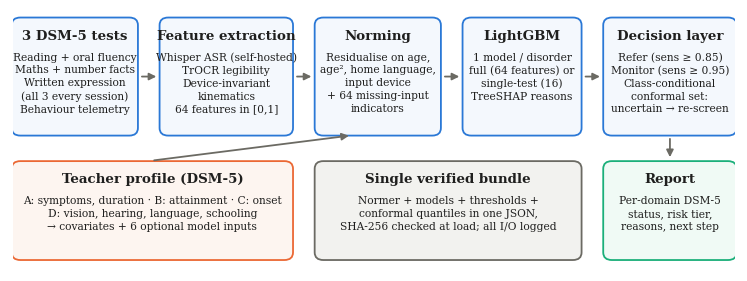

In [2]:
# ---- Fig. 1: system / screening pipeline diagram ----
fig, ax = plt.subplots(figsize=(COL2, 2.55)); ax.set_xlim(0, 100); ax.set_ylim(0, 40); ax.axis("off")
def box(x, y, w, h, title, body, fc="#f4f8fd", ec="#2a78d6"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.25,rounding_size=1.2", fc=fc, ec=ec, lw=1))
    ax.text(x + w/2, y + h - 1.6, title, ha="center", va="top", fontsize=7.4, weight="bold", color=INK)
    ax.text(x + w/2, y + h - 5.2, body, ha="center", va="top", fontsize=5.9, color=INK, linespacing=1.35)
def arrow(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1))
box(0,   21, 17, 18, "3 DSM-5 tests", "Reading + oral fluency\nMaths + number facts\nWritten expression\n(all 3 every session)\nBehaviour telemetry")
box(20.5,21, 18, 18, "Feature extraction", "Whisper ASR (self-hosted)\nTrOCR legibility\nDevice-invariant\nkinematics\n64 features in [0,1]")
box(42,  21, 17, 18, "Norming", "Residualise on age,\nage², home language,\ninput device\n+ 64 missing-input\nindicators")
box(62.5,21, 16, 18, "LightGBM", "1 model / disorder\nfull (64 features) or\nsingle-test (16)\nTreeSHAP reasons")
box(82,  21, 18, 18, "Decision layer", "Refer (sens ≥ 0.85)\nMonitor (sens ≥ 0.95)\nClass-conditional\nconformal set:\nuncertain → re-screen")
box(0,   1.5, 38.5, 15, "Teacher profile (DSM-5)", "A: symptoms, duration · B: attainment · C: onset\nD: vision, hearing, language, schooling\n→ covariates + 6 optional model inputs",
    fc="#fdf5f0", ec="#eb6834")
box(42,  1.5, 36.5, 15, "Single verified bundle", "Normer + models + thresholds +\nconformal quantiles in one JSON,\nSHA-256 checked at load; all I/O logged",
    fc="#f2f2ef", ec=MUTED)
box(82,  1.5, 18, 15, "Report", "Per-domain DSM-5\nstatus, risk tier,\nreasons, next step", fc="#f0faf5", ec="#1baf7a")
for x0, x1 in [(17.3, 20.3), (38.8, 41.8), (59.3, 62.3), (78.8, 81.8)]:
    arrow(x0, 30, x1, 30)
arrow(19, 16.8, 47, 20.8); arrow(91, 20.8, 91, 16.8)
fig.savefig(FIG / "fig1_system.png"); plt.show()

*Fig. 1. SwarSetu screening path. Task telemetry is converted into 64 features, normed for age, language and device, scored by one LightGBM model per disorder and mapped to referral tiers with conformal uncertainty. The teacher profile supplies covariates and DSM-5 Criteria A, C and D, which the tests cannot observe.*

## IV. Realistic Synthetic Cohorts

### A. Why the original benchmark was too easy
The original generator lowered all 16 features of a disorder's block by a constant and then min–max normalised the dataset. The stated effect size of 0.6 was applied in units whose noise SD was 0.3, so the median per-feature Cohen's *d* was 1.50–1.63 and prevalence was 16–21% instead of the stated 15%. Plain logistic regression reached test AUROCs of 0.96–0.97, so the benchmark could not separate models: any reasonable classifier looked excellent.

### B. Generative model
Each child has five correlated latent abilities: reading/phonology *R*, number sense *M*, graphomotor control *W*, executive attention *E* and processing speed *S* (ρ<sub>RM</sub> = 0.55, ρ<sub>RW</sub> = 0.40, others 0.25–0.40). Following the liability-threshold model of quantitative genetics, disorder *k* is present when its liability falls below the prevalence quantile:

$$\ell_k = r\,\tilde z_k + \sqrt{1-r^2}\,\varepsilon_k,\qquad y_k = \mathbb{1}\left[\ell_k < \Phi^{-1}(\pi_k)\right], \tag{1}$$

where $\tilde z_k$ is the standardised primary latent (*R*, *M*, or 0.85*W* + 0.25*R*), *r* = 0.9 is diagnostic reliability and π = (0.08, 0.06, 0.07). Comorbidity is not imposed; it emerges from the latent correlations: P(dyscalculia | dyslexia) = 0.22, P(dyslexia | dyscalculia) = 0.29 and P(dyslexia | dysgraphia) = 0.30, within published ranges [2].

The 64 features keep the semantics, polarity, defaults and formulas of the production extractors. Each is a noisy combination of one or more latents (loadings 0.15–0.75), with deliberate cross-domain loadings (e.g. word problems load on *M* and *R*). Median per-feature effect sizes are *d* = 0.77, 0.91 and 0.81 — moderate, rather than the near-perfect separation of the original. The generator further adds:

- *development*: raw skills rise by 0.25 SD per year from age 7 to 13;
- *home language*: 60% of children are Hindi-dominant and score 0.35 SD lower on English phonological and comprehension items *without* a disorder;
- *input device*: 70% use a finger, so pen pressure is unavailable and kinematics are noisier;
- *measurement*: binomial item scores (7–30 items), a reading-speed ceiling hit by 38% of children, 8% missing items and 10% skipped modules filled with the extractor defaults;
- *reference standard*: 10% of true cases are labelled negative and 1% of typical children positive.

An external site (Site B) shifts every factor: younger children, 85% Hindi-dominant, 95% finger input, extra noise, more missing data and 25% higher prevalence. Because of label noise, an oracle that knows each child's true latent reaches only AUROC 0.89–0.91, which is the realistic ceiling for any model.

## V. Screening Pipeline

**Norming.** Psychometric tests are scored against age norms; we do the same statistically. On typically developing training children, each feature $x_j$ is regressed on covariates $c = (a, a^2, h, f)$ — age, age squared, Hindi-dominant and finger input — and the model receives the standardised residual

$$z_j = \left(x_j - \hat\beta_j^{\top} c\right) / \hat\sigma_j . \tag{2}$$

A seven-year-old who reads slowly is therefore compared with other seven-year-olds, not with twelve-year-olds. Unknown covariates are imputed with training means, and 15% of training covariates are masked so that the model learns to handle that case.

**Model and training objective.** The 64 normed features plus 64 missing-input indicators feed one LightGBM classifier [11] per disorder (300 trees, 7 leaves, learning rate 0.03, row/column subsampling 0.8/0.7). The three classifiers are trained on the same children, whose label vector $\mathbf y_i=(y_{i1},y_{i2},y_{i3})$ marks dyslexia, dyscalculia and dysgraphia, so a comorbid child is a positive example for several models. Booster $F_k$ minimises the regularised binary log-loss

$$\mathcal L_k=-\frac1n\sum_{i=1}^{n}\Bigl[y_{ik}\log p_{ik}+(1-y_{ik})\log(1-p_{ik})\Bigr]+\lambda\sum_{t}\lVert \mathbf w_t\rVert^2, \tag{3}$$

with $p_{ik}=\sigma(F_k(\mathbf z_i))$, leaf weights $\mathbf w_t$ of tree $t$ and $\lambda=1$. All three models share the normer, features and splits (stratified on the eight label combinations). The *comprehensive* models use all 64 features and score every full three-test session; three *single-test* models use only their 16-feature block for teacher-permitted single tests, replacing the 0.5-fill strategy.

**Operating points and uncertainty.** On held-out validation data we set a *refer* threshold at sensitivity ≥ 0.85 and a *monitor* threshold at ≥ 0.95, giving three reachable risk tiers. For each class separately we compute split-conformal quantiles of the score 1 − p̂(true class) (class-conditional, α = 0.1) [8]. The resulting prediction set — {0}, {1} or {0, 1} — is reported as screen-negative, screen-positive or *uncertain: re-screen*. TreeSHAP values [12] name the skills that drove each result.

**Packaging.** Normer, models, thresholds and conformal quantiles are saved in one JSON bundle with a SHA-256 checksum that is verified against the extractors' feature names at load time. Every input, feature vector, prediction and model version is stored, together with any later confirmed diagnosis, so that real labelled data accumulate for re-training.

## VI. Handwriting, Speech and DSM-5 Alignment

### A. Device-invariant dysgraphia analysis
The original scorer computed smoothness, tremor and precision on raw pointer samples. Touch and pen screens report 120–240 events per second, so consecutive samples are 1–2 px apart and pixel quantisation looks like tremor; its "precision" ratio (chord/path) also penalised every curved letter. We replace it with four domains per drawing. *Motor control:* each stroke is resampled to 1 px, lightly smoothed and resampled at 3% of the stroke's own size; with $L_\sigma$ the path length after Gaussian smoothing of width σ samples, the jitter index $J = L_1 / L_4 - 1$ measures the extra length added by high-frequency oscillation and is independent of sampling rate, screen size and letter size. *Fluency:* speed in letter-heights per second, mid-stroke halts and pauses, with per-device expectations. *Layout:* robust slope and scatter of letter baselines. *Legibility:* a self-hosted TrOCR recogniser [13] reads each item, scored as 1 − CER against the prompt. Domain scores are weighted 0.40/0.25/0.20/0.15 (legibility, fluency, motor, layout); any domain below 60 raises the risk to at least moderate.

### B. Speech
Spoken answers are transcribed by a self-hosted Whisper model [14] (large-v3-turbo on GPU, small on CPU), so children's audio never leaves the school's server. Audio is segmented at pauses in the browser; silent clips return an empty transcript instead of a hallucinated one.

### C. DSM-5 criteria and specifiers
DSM-5 requires (A) symptoms persisting for six months despite targeted help, (B) attainment well below age expectations, (C) onset in the school years, and (D) that difficulties are not better explained by intellectual disability, uncorrected vision or hearing, lack of proficiency in the language of instruction or inadequate instruction [1]. Tests can only speak to Criterion B. A teacher profile therefore records date of birth, home language, language of instruction, device, and items for Criteria A, C and D; age, language and device feed the model's covariates, and six questionnaire items (symptom frequency and teacher-rated attainment per domain) enter as optional features.

Each test now reports the DSM-5 specifiers of its domain (Table I). *Oral reading fluency:* the child reads a graded passage aloud for up to one minute; the transcript is aligned with the passage by a semi-global edit distance that lets the child stop anywhere and does not count repetitions, and words correct per minute (WCPM) are compared with published norms [15]. *Number facts:* one minute of grade-appropriate facts gives correct facts per minute and retrieval time. *Written expression:* copying (legibility) is separated from dictation (spelling), a dictated sentence (capitalisation, punctuation) and, from Grade 3, a short composition rated by the teacher. When handwriting is weak but spelling and composition are not, the report points to a motor-coordination check rather than an SLD.

For each domain, the profile and latest screen give one of four statuses: *consistent* with DSM-5 (refer), *exclusion review* (a Criterion D factor could explain the difficulty — address it and re-screen), *partial* (missing criteria listed) or *not indicated*. Criterion D is applied per domain: limited proficiency in the language of instruction can explain reading and writing difficulties but not poor number sense.

In [3]:
# ---- Table I: DSM-5 specifiers and the tasks that measure them ----
spec = pd.DataFrame([
    ["Reading", "Word reading accuracy", "Phonological awareness, pseudowords; **passage word accuracy**"],
    ["",        "Reading rate / fluency", "**Oral reading: words correct per minute**"],
    ["",        "Comprehension", "Passage questions"],
    ["Writing", "Spelling accuracy", "**Dictated words and sentence**"],
    ["",        "Grammar and punctuation", "**Dictated sentence; composition**"],
    ["",        "Clarity / organisation", "**Composition (teacher rating)**"],
    ["Maths",   "Number sense", "Magnitude comparison, estimation, symbol mapping"],
    ["",        "Arithmetic facts", "**Number facts: correct/min, time per fact**"],
    ["",        "Fluent calculation", "**Number facts: accuracy**"],
    ["",        "Math reasoning", "Word problems, sequences"],
], columns=["Domain", "DSM-5 specifier", "Task and measure (new tasks in bold)"])
show_table(spec, "TABLE I. DSM-5 specifiers and the SwarSetu tasks that measure them.")

**TABLE I. DSM-5 specifiers and the SwarSetu tasks that measure them.**

| Domain | DSM-5 specifier | Task and measure (new tasks in bold) |
|---|---|---|
| Reading | Word reading accuracy | Phonological awareness, pseudowords; **passage word accuracy** |
|  | Reading rate / fluency | **Oral reading: words correct per minute** |
|  | Comprehension | Passage questions |
| Writing | Spelling accuracy | **Dictated words and sentence** |
|  | Grammar and punctuation | **Dictated sentence; composition** |
|  | Clarity / organisation | **Composition (teacher rating)** |
| Maths | Number sense | Magnitude comparison, estimation, symbol mapping |
|  | Arithmetic facts | **Number facts: correct/min, time per fact** |
|  | Fluent calculation | **Number facts: accuracy** |
|  | Math reasoning | Word problems, sequences |

## VII. Evaluation Protocol

For each of five seeds we generate a cohort (*n* = 6000), split it 60/20/20 stratified on the eight label combinations, and generate a Site B cohort (*n* = 3000).

**Models.** Logistic regression (LR); LR with the three covariates; random forest; XGBoost; LightGBM on raw features; an MLP; the FT-Transformer retrained under a corrected protocol (best-weight restoration, warm-up, early stopping) with ASL+Dice, with ASL+Dice plus temperature scaling, and with binary cross-entropy (BCE); and the production pipeline. We also evaluate the originally deployed artefacts without retraining (D-rows).

**Metrics.** AUROC and AUPRC; Brier score and 10-bin expected calibration error (ECE); sensitivity, specificity and positive predictive value (PPV) at the validation-chosen refer threshold. Means ± SD are over seeds. Paired bootstrap 95% intervals resample each seed's test set 1000 times and recompute every model on the same resample.

**Learning curves and sensitivity analysis.** Learning curves train on 250–16 000 children (three seeds, fixed 6000-child test set). Because we designed the generator ourselves, we vary one assumption at a time — signal strength, missed diagnoses, diagnostic reliability, missing items, language shift, age slope and prevalence — giving 22 settings with three seeds each.

**DSM-5, reading fluency and handwriting.** The generator is extended with Criterion D factors (30% of children still developing and 10% with limited proficiency in the language of instruction; 5% vision and 3% hearing concerns) and simulated teacher ratings with halo and language bias. Reading fluency is tested with 2000 simulated readers per grade passed through a recogniser error model at word error rates (WER) of 0–20%. Handwriting is tested on synthetic writers drawn with human-like velocity profiles at device-realistic sampling rates: neat writers on pen (60 Hz), touch (144 Hz) and mouse, and four impaired profiles (tremor, stop-start, uneven size/drift, distorted letters), three writers each.

## VIII. Results

### A. Discrimination and significance
Table II gives the main comparison. Once retrained correctly, the FT-Transformer is no better than simple baselines: 0.804 (ASL+Dice) and 0.810 (BCE), against 0.807 for LR and 0.810 for random forest. Early stopping selected weights from about epoch 2 in every run: the network overfits 3600 children almost immediately. The production pipeline reaches 0.858, and paired bootstrap intervals (Table III) show it beats every other model — by +0.048 to +0.062 AUROC against unadjusted models, and by a small but consistent +0.007 against LR with the same covariates. On the shifted Site B its AUROC falls by only 0.012 and specificity at the transported threshold stays at 0.65, whereas unadjusted models fall to about 0.42. Without age and language information the pipeline drops to 0.803, the level of the unadjusted models: the application *must* collect these covariates.

In [4]:
# ---- Table II: main comparison (mean ± SD over five seeds) ----
rows = []
dyn = dynamics["comparison"]
order = [("LightGBM pipeline (production)", dyn["LightGBM pipeline (production)"]),
         ("  same, covariates unknown", dyn["LightGBM pipeline, covariates unknown"])]
main = {r["model"]: r for r in summary["main"]}
names = {"LR + demographics": "LR + demographics", "Logistic Regression": "Logistic regression",
         "Random Forest": "Random forest", "XGBoost": "XGBoost", "LightGBM": "LightGBM (raw features)",
         "MLP (sklearn)": "MLP", "FT-Transformer (ASL+Dice)": "FT-Transformer (ASL+Dice)",
         "FT-Transformer (ASL+Dice) + TS": "FT-Transformer (ASL+Dice) + TS",
         "FT-Transformer (BCE)": "FT-Transformer (BCE)", "D1 Deployed FT (as served)": "D1 Deployed FT, as served",
         "D3 Deployed single-test (0.5 fill)": "D3 Deployed single test (0.5 fill)",
         "D4 Legacy *_nn_model (random weights)": "D4 Legacy random-weight NN"}
order += [(v, main[k]) for k, v in names.items()]
for name, r in order:
    rows.append([name] + [pm(r[m]) for m in ["auroc", "auprc", "ece", "sens", "spec", "ppv", "ext_auroc", "ext_spec"]])
t2 = pd.DataFrame(rows, columns=["Model", "AUROC", "AUPRC", "ECE", "Sens.", "Spec.", "PPV", "Ext. AUROC", "Ext. Spec."])
show_table(t2, "TABLE II. Macro-averaged test results over five seeds (mean ± SD); operating point chosen on validation "
               "data for sensitivity ≥ 0.85. Ext. = distribution-shifted Site B. D-rows = originally deployed artefacts, not retrained.")

**TABLE II. Macro-averaged test results over five seeds (mean ± SD); operating point chosen on validation data for sensitivity ≥ 0.85. Ext. = distribution-shifted Site B. D-rows = originally deployed artefacts, not retrained.**

| Model | AUROC | AUPRC | ECE | Sens. | Spec. | PPV | Ext. AUROC | Ext. Spec. |
|---|---|---|---|---|---|---|---|---|
| LightGBM pipeline (production) | 0.858 ± 0.012 | 0.429 ± 0.022 | 0.017 ± 0.003 | 0.856 ± 0.021 | 0.685 ± 0.025 | 0.178 ± 0.014 | 0.846 ± 0.006 | 0.654 ± 0.039 |
|   same, covariates unknown | 0.803 ± 0.006 | 0.322 ± 0.014 | 0.041 ± 0.006 | 0.844 ± 0.020 | 0.574 ± 0.026 | 0.135 ± 0.008 | 0.812 ± 0.003 | 0.364 ± 0.032 |
| LR + demographics | 0.851 ± 0.014 | 0.397 ± 0.016 | 0.226 ± 0.011 | 0.867 ± 0.039 | 0.658 ± 0.032 | 0.166 ± 0.010 | 0.839 ± 0.008 | 0.638 ± 0.046 |
| Logistic regression | 0.807 ± 0.013 | 0.318 ± 0.025 | 0.261 ± 0.009 | 0.859 ± 0.030 | 0.563 ± 0.032 | 0.136 ± 0.007 | 0.804 ± 0.007 | 0.424 ± 0.042 |
| Random forest | 0.810 ± 0.008 | 0.310 ± 0.019 | 0.035 ± 0.002 | 0.833 ± 0.013 | 0.603 ± 0.027 | 0.143 ± 0.012 | 0.817 ± 0.006 | 0.416 ± 0.033 |
| XGBoost | 0.796 ± 0.010 | 0.302 ± 0.021 | 0.096 ± 0.005 | 0.849 ± 0.018 | 0.542 ± 0.022 | 0.128 ± 0.008 | 0.793 ± 0.011 | 0.398 ± 0.037 |
| LightGBM (raw features) | 0.799 ± 0.012 | 0.307 ± 0.026 | 0.047 ± 0.002 | 0.857 ± 0.028 | 0.548 ± 0.022 | 0.132 ± 0.007 | 0.798 ± 0.009 | 0.422 ± 0.035 |
| MLP | 0.741 ± 0.007 | 0.242 ± 0.018 | 0.075 ± 0.004 | 0.858 ± 0.021 | 0.405 ± 0.029 | 0.103 ± 0.005 | 0.739 ± 0.007 | 0.339 ± 0.033 |
| FT-Transformer (ASL+Dice) | 0.804 ± 0.016 | 0.317 ± 0.033 | 0.275 ± 0.017 | 0.837 ± 0.023 | 0.586 ± 0.012 | 0.138 ± 0.007 | 0.810 ± 0.011 | 0.424 ± 0.017 |
| FT-Transformer (ASL+Dice) + TS | 0.804 ± 0.016 | 0.317 ± 0.033 | 0.314 ± 0.014 | 0.837 ± 0.023 | 0.586 ± 0.012 | 0.138 ± 0.007 | 0.810 ± 0.011 | 0.424 ± 0.017 |
| FT-Transformer (BCE) | 0.810 ± 0.012 | 0.333 ± 0.022 | 0.021 ± 0.003 | 0.846 ± 0.024 | 0.587 ± 0.037 | 0.141 ± 0.010 | 0.819 ± 0.004 | 0.420 ± 0.030 |
| D1 Deployed FT, as served | 0.691 ± 0.015 | 0.189 ± 0.032 | 0.195 ± 0.003 | 0.852 ± 0.036 | 0.327 ± 0.037 | 0.090 ± 0.002 | 0.674 ± 0.007 | 0.261 ± 0.020 |
| D3 Deployed single test (0.5 fill) | 0.764 ± 0.015 | 0.274 ± 0.019 | 0.192 ± 0.003 | 0.847 ± 0.029 | 0.475 ± 0.040 | 0.114 ± 0.005 | 0.764 ± 0.004 | 0.303 ± 0.047 |
| D4 Legacy random-weight NN | 0.475 ± 0.013 | 0.096 ± 0.008 | 0.654 ± 0.002 | 0.833 ± 0.035 | 0.103 ± 0.024 | 0.068 ± 0.001 | 0.492 ± 0.011 | 0.123 ± 0.027 |

In [5]:
# ---- Table III: paired bootstrap, production pipeline minus each model ----
bs = sensboot["bootstrap"]["lightgbm_minus_model_auroc"]
t3 = pd.DataFrame([[m, f"{d['diff'][0]:+.3f} [{d['diff'][1]:+.3f}, {d['diff'][2]:+.3f}]",
                    "< 0.001" if d["p_le_0"] < 0.001 else f"{d['p_le_0']:.3f}"] for m, d in bs.items()],
                  columns=["Compared with", "Δ macro AUROC [95% CI]", "P(Δ ≤ 0)"])
show_table(t3, "TABLE III. Paired bootstrap (1000 resamples × 5 seeds): production pipeline minus each model.")

**TABLE III. Paired bootstrap (1000 resamples × 5 seeds): production pipeline minus each model.**

| Compared with | Δ macro AUROC [95% CI] | P(Δ ≤ 0) |
|---|---|---|
| LR + demographics | +0.007 [+0.002, +0.012] | 0.001 |
| Logistic regression | +0.051 [+0.043, +0.059] | < 0.001 |
| Random forest | +0.048 [+0.040, +0.057] | < 0.001 |
| XGBoost | +0.062 [+0.053, +0.071] | < 0.001 |
| FT-Transformer (ASL+Dice) | +0.053 [+0.045, +0.063] | < 0.001 |
| FT-Transformer (BCE) | +0.048 [+0.040, +0.057] | < 0.001 |

### B. Results for each disorder
Table IIIb reports the deployed bundle (trained on 20 000 children, 4000-child held-out test set) for each disorder separately. The comprehensive model reaches AUROC 0.855, 0.853 and 0.859 for dyslexia, dyscalculia and dysgraphia and exceeds the FT-Transformer for every disorder by 0.04–0.07. Each disorder model is calibrated (ECE ≤ 0.012) with NPV 0.98–0.99. Conformal sets cover 0.94–0.95 of affected children for dyslexia and dyscalculia but 0.88 for dysgraphia, slightly below the 0.90 target. Single-test models lose at most 0.004 AUROC, but only the full three-test session can reveal a co-occurring difficulty in another domain. Fig. 2b shows the training dynamics of all three models: validation log-loss reaches its minimum after 129, 142 and 184 iterations (mean over five seeds) and rises by only about 0.003 by iteration 300, while validation AUROC plateaus for every disorder.

### C. Learning curves and sensitivity to the generator
LightGBM is best at every training size (Fig. 2). With 250 children it reaches 0.811, against 0.760 for LR with covariates and 0.697 for the FT-Transformer; the transformer still trails at 16 000 children (0.828 vs 0.868). Because real learning-disability datasets are small, this low-data regime is the relevant one.

Fig. 3 varies each generator assumption. The pipeline is best, or within 0.005 of the best model, in all 22 settings; it beats the ASL FT-Transformer in 22/22 and the BCE FT-Transformer in 21/22, and the model ranking is stable (mean Kendall τ = 0.89 against the baseline ranking). One setting qualifies this: with no age effect, all models converge to 0.84–0.85. The pipeline's advantage therefore comes mainly from *norming away the age and language confounds*, not from the learning algorithm — an important attribution for anyone adapting the method.

**TABLE IIIb. Per-disorder results of the deployed bundle (4000-child held-out test). Last two columns: five-seed benchmark.**

| Disorder | AUROC compr. | AUROC single | AUPRC | ECE | Sens. | Spec. | PPV | NPV | Coverage +/− | Best iter. | LR+cov AUROC | FT (ASL) AUROC |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Dyslexia | 0.855 | 0.855 | 0.421 | 0.012 | 0.878 | 0.639 | 0.178 | 0.983 | 0.95/0.90 | 129 | 0.857 | 0.808 |
| Dyscalculia | 0.853 | 0.851 | 0.403 | 0.009 | 0.858 | 0.675 | 0.151 | 0.986 | 0.94/0.91 | 142 | 0.850 | 0.817 |
| Dysgraphia | 0.859 | 0.855 | 0.426 | 0.008 | 0.825 | 0.736 | 0.197 | 0.982 | 0.88/0.91 | 184 | 0.845 | 0.789 |

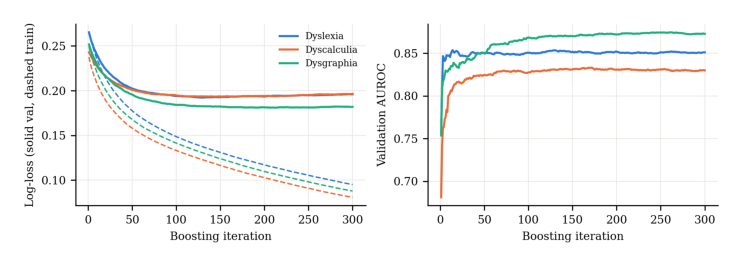

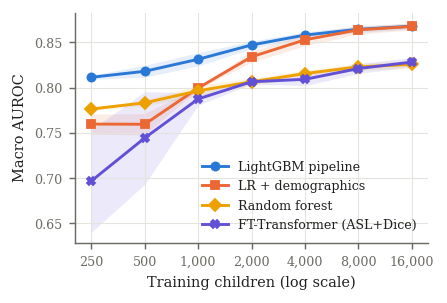

In [6]:
# ---- Table IIIb: per-disorder results of the deployed bundle ----
bundle = json.load(open(ROOT / "backend/models/screening_bundle.json", encoding="utf-8"))
vr, pdis = bundle["validation_report"], summary["per_disorder"]
rows = []
for D in ["Dyslexia", "Dyscalculia", "Dysgraphia"]:
    f, sg = vr["full"][D], vr[D.lower()][D]
    rows.append([D, f"{f['auroc']:.3f}", f"{sg['auroc']:.3f}", f"{f['auprc']:.3f}", f"{f['ece']:.3f}", f"{f['refer_sens']:.3f}",
                 f"{f['refer_spec']:.3f}", f"{f['refer_ppv']:.3f}", f"{f['refer_npv']:.3f}",
                 f"{f['conformal_coverage_pos']:.2f}/{f['conformal_coverage_neg']:.2f}",
                 f"{dynamics['best_iteration_by_val_logloss'][D]:.0f}",
                 f"{pdis['LR + demographics'][D]['auroc'][0]:.3f}", f"{pdis['FT-Transformer (ASL+Dice)'][D]['auroc'][0]:.3f}"])
show_table(pd.DataFrame(rows, columns=["Disorder", "AUROC compr.", "AUROC single", "AUPRC", "ECE", "Sens.", "Spec.", "PPV", "NPV",
                                       "Coverage +/−", "Best iter.", "LR+cov AUROC", "FT (ASL) AUROC"]),
           "TABLE IIIb. Per-disorder results of the deployed bundle (4000-child held-out test). Last two columns: five-seed benchmark.")

# ---- Fig. 2b: boosting dynamics for all three disorders (written by lightgbm_dynamics.py, seed 0) ----
import matplotlib.image as mpimg, shutil
src = ROOT / "backend/reports/realistic_eval/results/figures/fig_lgbm_boosting.png"
shutil.copy(src, FIG / "fig2_boosting.png")
img = mpimg.imread(src); fig, ax = plt.subplots(figsize=(COL2, COL2 * img.shape[0] / img.shape[1])); ax.imshow(img); ax.axis("off"); plt.show()

lc = dynamics["learning_curves"]
ren = {"LightGBM pipeline": "LightGBM pipeline", "LR + demographics": "LR + demographics",
       "Random forest (raw)": "Random forest", "FT-Transformer (ASL+Dice)": "FT-Transformer (ASL+Dice)"}
fig, ax = plt.subplots(figsize=(COL1, 2.3))
for k, lab in ren.items():
    n = np.array([int(x) for x in lc[k]]); m = np.array([v[0] for v in lc[k].values()]); s = np.array([v[1] for v in lc[k].values()])
    c, mk = STYLE[lab]
    ax.fill_between(n, m - s, m + s, color=c, alpha=0.12, lw=0)
    ax.plot(n, m, marker=mk, color=c, label=lab)
ax.set_xscale("log"); ax.set_xticks(n); ax.set_xticklabels([f"{x:,}" for x in n])
ax.set_xlabel("Training children (log scale)"); ax.set_ylabel("Macro AUROC"); ax.minorticks_off()
ax.legend(frameon=False, loc="lower right")
fig.savefig(FIG / "fig2_learning_curves.png"); plt.show()

*Fig. 2b. Training (dashed) and validation (solid) log-loss and validation AUROC per boosting iteration for the three disorder models (seed 0).*

*Fig. 2. Macro AUROC versus training-set size (mean ± SD over three seeds, fixed 6000-child test set).*

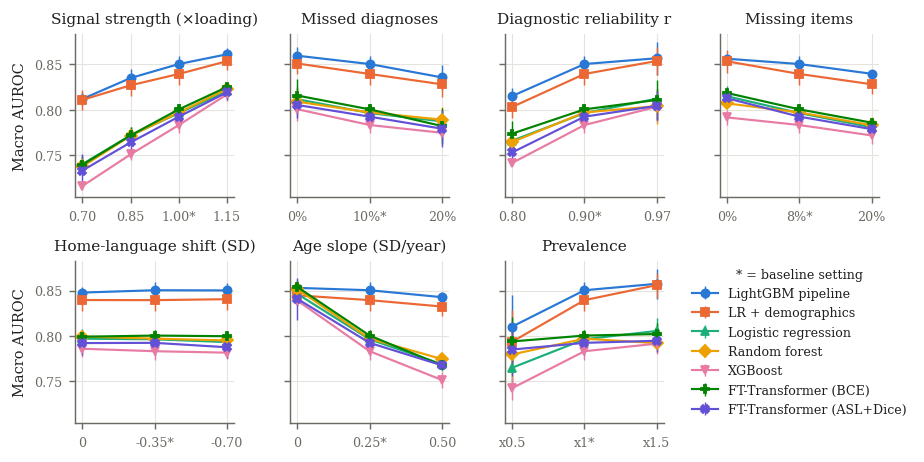

In [7]:
# ---- Fig. 3: generator sensitivity analysis ----
rows_ = sensboot["sensitivity"]["rows"]
factors = list(dict.fromkeys(r["factor"] for r in rows_))
smap = {"LightGBM pipeline": "LightGBM pipeline", "LR + demographics": "LR + demographics",
        "Logistic regression": "Logistic regression", "Random forest": "Random forest", "XGBoost": "XGBoost",
        "FT-Transformer (BCE)": "FT-Transformer (BCE)", "FT-Transformer (ASL+Dice)": "FT-Transformer (ASL+Dice)"}
def lvl_key(s):
    try: return float(s.replace("%", "").replace("x", ""))
    except ValueError: return 0.0
TITLES = {"signal strength (loading scale)": "Signal strength (×loading)", "missed diagnoses (label FN rate)": "Missed diagnoses",
          "diagnostic reliability r": "Diagnostic reliability r", "missing items": "Missing items",
          "home-language shift (SD)": "Home-language shift (SD)", "age slope (SD/year)": "Age slope (SD/year)",
          "prevalence": "Prevalence"}
fig, axes = plt.subplots(2, 4, figsize=(COL2, 3.6), sharey=True)
for ax, f in zip(axes.flat, factors):
    rr = sorted([r for r in rows_ if r["factor"] == f], key=lambda r: lvl_key(r["level"]))
    if f.startswith("home-language"): rr = rr[::-1]          # 0 -> -0.35 -> -0.70 (increasing shift)
    x = np.arange(len(rr))
    for key, lab in smap.items():
        c, mk = STYLE[lab]
        ax.errorbar(x, [r[key][0] for r in rr], yerr=[r[key][1] for r in rr], color=c, marker=mk, lw=1.2, capsize=0,
                    elinewidth=0.8, label=lab)
    ax.set_xticks(x); ax.set_xticklabels([r["level"] + ("*" if r["baseline"] else "") for r in rr])
    ax.set_title(TITLES.get(f, f), color=INK)
axes[0, 0].set_ylabel("Macro AUROC"); axes[1, 0].set_ylabel("Macro AUROC")
axes.flat[-1].axis("off")
h, l = axes[0, 0].get_legend_handles_labels()
axes.flat[-1].legend(h, l, frameon=False, loc="center", title="* = baseline setting", title_fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "fig3_sensitivity.png"); plt.show()

*Fig. 3. Generator sensitivity analysis: macro AUROC (mean ± SD, three seeds) as one assumption is varied at a time; * marks the baseline setting.*

### D. Operating point, calibration and uncertainty
At sensitivity 0.86 the pipeline has specificity 0.685, PPV 0.178 (95% CI 0.168–0.188) and NPV 0.984 at a prevalence of 6–8%. In a school of 500 children this means about 180 referrals per disorder (34 true and 145 false positives) to find 34 of the 40 affected children. The tool is therefore a first, high-sensitivity stage that rules children *out* and prioritises observation — not a referral trigger on its own.

The pipeline's probabilities are calibrated without post-processing (ECE 0.017). ASL shifts probabilities upward (ECE 0.275), and temperature scaling makes this *worse* (0.314), because a single temperature rescales logits but cannot remove a bias (Fig. 4). The originally deployed "90% guaranteed" intervals, with hard-coded widths, covered 0% of test children; standard split-conformal sets covered 90% overall but only 52–64% of affected children. The class-conditional sets cover 0.94 of affected and 0.90 of unaffected children. About a third to a half of children receive the *uncertain* set — an honest reflection of the data's limits that leads to a re-screen rather than a confident wrong answer.

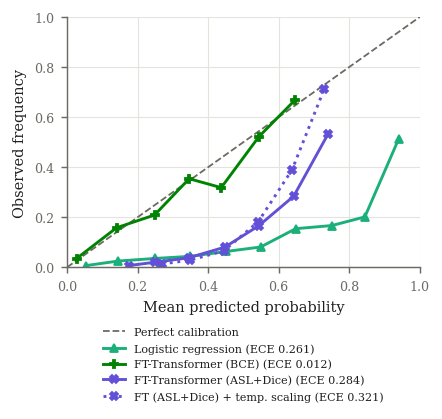

In [8]:
# ---- Fig. 4: reliability diagram (seed 0, all disorders pooled) ----
P = np.load(RES / "seed0_predictions.npz", allow_pickle=True)
y = P["y_test"].ravel()
models = [("Logistic Regression", "Logistic regression"), ("FT-Transformer (BCE)", "FT-Transformer (BCE)"),
          ("FT-Transformer (ASL+Dice)", "FT-Transformer (ASL+Dice)")]
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(COL1, 2.5))
ax.plot([0, 1], [0, 1], ls="--", color=MUTED, lw=1, label="Perfect calibration")
for key, lab in models:
    p = P["test::" + key].ravel(); idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
    xs, ys = [], []
    for b in range(10):
        m = idx == b
        if m.sum() >= 15: xs.append(p[m].mean()); ys.append(y[m].mean())
    ece = sum(abs(p[idx == b].mean() - y[idx == b].mean()) * (idx == b).mean() for b in range(10) if (idx == b).any())
    c, mk = STYLE[lab]; ax.plot(xs, ys, marker=mk, color=c, label=f"{lab} (ECE {ece:.3f})")
p = P["test::FT-Transformer (ASL+Dice) + TS"].ravel(); idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
xs = [p[idx == b].mean() for b in range(10) if (idx == b).sum() >= 15]; ys = [y[idx == b].mean() for b in range(10) if (idx == b).sum() >= 15]
ece = sum(abs(p[idx == b].mean() - y[idx == b].mean()) * (idx == b).mean() for b in range(10) if (idx == b).any())
ax.plot(xs, ys, marker="X", ls=":", color=STYLE["FT-Transformer (ASL+Dice)"][0], label=f"FT (ASL+Dice) + temp. scaling (ECE {ece:.3f})")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed frequency"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=6.2, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1)
fig.savefig(FIG / "fig4_calibration.png"); plt.show()

*Fig. 4. Reliability diagram (seed 0, three disorders pooled, bins with ≥ 15 children). ASL-trained models overestimate risk and temperature scaling does not fix the bias; BCE lies close to the diagonal.*

### E. Single tests, missing data and fairness
Single-test models reach 0.848–0.855 AUROC, against 0.854–0.860 for the comprehensive model, and clearly beat the original 0.5-fill path (0.741–0.781) — so a teacher can run only the reading test without a large loss. With up to 40% additional items removed at test time, the pipeline falls from 0.858 to 0.813, degrading less than LR (to 0.757) and staying ahead of every model (Fig. 5a).

Without covariates, Hindi-dominant children without dyslexia were flagged more often than English-dominant ones (false-positive rate 0.48 vs 0.38 for the FT-Transformer), and 7–8-year-olds far more often than 11–12-year-olds (0.62 vs 0.25; Fig. 5b). Covariate adjustment narrows both gaps (LR + demographics: 0.36 vs 0.34 by language, 0.37 vs 0.33 by age); for the deployed bundle, false-positive rates for English- vs Hindi-dominant children are 0.32 vs 0.39 (dyslexia), 0.32 vs 0.33 (dyscalculia) and 0.25 vs 0.27 (dysgraphia), and the age gap shrinks to 0.40 vs 0.31 for dyslexia.

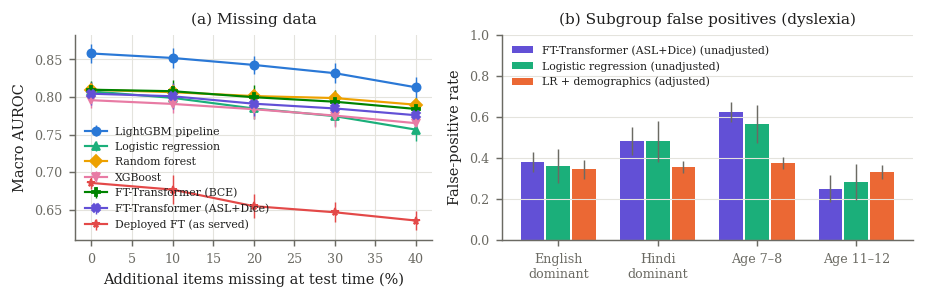

In [9]:
# ---- Fig. 5: (a) robustness to missing items, (b) false-positive rate by subgroup ----
fig, (a, b) = plt.subplots(1, 2, figsize=(COL2, 2.35), gridspec_kw={"width_ratios": [1, 1.15]})
miss = summary["missing"]; rates = [0.0, 0.1, 0.2, 0.3, 0.4]
series = [("LightGBM pipeline", dynamics["missing_macro_auroc"]), ("Logistic regression", miss["Logistic Regression"]),
          ("Random forest", miss["Random Forest"]), ("XGBoost", miss["XGBoost"]),
          ("FT-Transformer (BCE)", miss["FT-Transformer (BCE)"]), ("FT-Transformer (ASL+Dice)", miss["FT-Transformer (ASL+Dice)"]),
          ("Deployed FT (as served)", miss["D1 Deployed FT (as served)"])]
for lab, d in series:
    m = [d[str(r)][0] for r in rates]; s = [d[str(r)][1] for r in rates]; c, mk = STYLE[lab]
    a.errorbar([r * 100 for r in rates], m, yerr=s, color=c, marker=mk, lw=1.2, elinewidth=0.8, label=lab)
a.set_xlabel("Additional items missing at test time (%)"); a.set_ylabel("Macro AUROC"); a.set_title("(a) Missing data")
a.legend(frameon=False, fontsize=6, loc="lower left", ncol=1)

fair = summary["fairness"]; groups = [("fpr_en", "English\ndominant"), ("fpr_hi", "Hindi\ndominant"),
                                      ("fpr_7_8", "Age 7–8"), ("fpr_11_12", "Age 11–12")]
mods = [("FT-Transformer (ASL+Dice)", "FT-Transformer (ASL+Dice)", "unadjusted"),
        ("Logistic Regression", "Logistic regression", "unadjusted"), ("LR + demographics", "LR + demographics", "adjusted")]
w = 0.26; x = np.arange(len(groups))
for i, (key, lab, kind) in enumerate(mods):
    vals = [fair[key]["Dyslexia"][g][0] for g, _ in groups]; errs = [fair[key]["Dyslexia"][g][1] for g, _ in groups]
    c, _ = STYLE[lab]
    b.bar(x + (i - 1) * w, vals, w * 0.92, yerr=errs, color=c, error_kw=dict(lw=0.8, ecolor=MUTED), label=f"{lab} ({kind})")
b.set_xticks(x); b.set_xticklabels([g for _, g in groups]); b.set_ylabel("False-positive rate")
b.set_title("(b) Subgroup false positives (dyslexia)"); b.legend(frameon=False, fontsize=6, loc="upper left")
b.set_ylim(0, 1.0); b.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "fig5_missing_fairness.png"); plt.show()

*Fig. 5. (a) Macro AUROC as additional items are removed at test time (mean ± SD, five seeds). (b) Dyslexia false-positive rate among children without dyslexia, by home language and age, for unadjusted and covariate-adjusted models.*

### F. Handwriting analysis
Table IV compares the original and new dysgraphia scorers on synthetic handwriting (Fig. 6). The original scorer gave neat writing 85–86/100 on a 60 Hz pen but only 60–62 on a touch screen and 54–56 with a mouse — *below* the scores it gave writers with tremor (78–82). It was measuring the device, not the child. The new scorer gives all nine neat writers 99–100 and low risk on every device, flags all nine tremor, stop-start and layout writers and 2 of 3 distorted writers, and in each case its lowest domain matches the simulated deficit. Self-hosted recogniser legibility was 1.00 for neat writing on every device, 0.88 for size/drift, 0.79 for distorted and 0.70 for tremor writing.

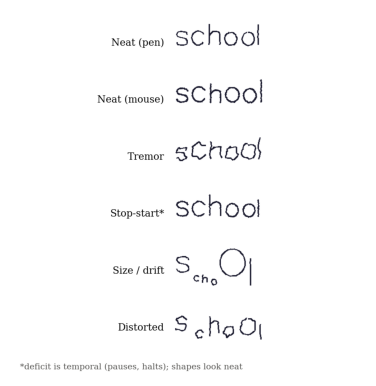

**TABLE IV. Dysgraphia scores (0–100) with the original and new analysis; risk L/M/H = low/moderate/high.**

| Profile (3 writers each) | Original score | New score (risk) | Legibility (1 − CER) |
|---|---|---|---|
| Neat, pen (60 Hz) | 85–86 | 100 (L, L, L) | 1.00 |
| Neat, touch (144 Hz) | 60–62 | 100 (L, L, L) | 1.00 |
| Neat, mouse | 54–56 | 99–100 (L, L, L) | 1.00 |
| Tremor | 78–82 | 72–78 (M, H, H) | 0.70 |
| Stop-start | 56–58 | 86–90 (M, M, M) | 1.00 |
| Size / drift | 81–84 | 75–86 (H, H, M) | 0.88 |
| Distorted letters | 69–72 | 75–88 (H, M, L) | 0.79 |

In [10]:
# ---- Fig. 6: synthetic handwriting samples (generated by the handwriting test fixtures) ----
import matplotlib.image as mpimg, shutil
src = OLD_FIGS / "fig_handwriting_samples.png"
shutil.copy(src, FIG / "fig6_handwriting_samples.png")
img = mpimg.imread(src); fig, ax = plt.subplots(figsize=(COL1, COL1 * img.shape[0] / img.shape[1])); ax.imshow(img); ax.axis("off"); plt.show()

# ---- Table IV: dysgraphia scores, original vs new analysis ----
leg = load("handwriting_legibility.json")
t4 = pd.DataFrame([
    ["Neat, pen (60 Hz)",     "85–86", "100 (L, L, L)",    leg["typical"]["mean"]],
    ["Neat, touch (144 Hz)",  "60–62", "100 (L, L, L)",    leg["typical_touch"]["mean"]],
    ["Neat, mouse",           "54–56", "99–100 (L, L, L)", leg["typical_mouse"]["mean"]],
    ["Tremor",                "78–82", "72–78 (M, H, H)",  leg["tremor"]["mean"]],
    ["Stop-start",            "56–58", "86–90 (M, M, M)",  leg["dysfluent"]["mean"]],
    ["Size / drift",          "81–84", "75–86 (H, H, M)",  leg["spatial"]["mean"]],
    ["Distorted letters",     "69–72", "75–88 (H, M, L)",  leg["illegible"]["mean"]],
], columns=["Profile (3 writers each)", "Original score", "New score (risk)", "Legibility (1 − CER)"])
t4["Legibility (1 − CER)"] = t4["Legibility (1 − CER)"].map(lambda v: f"{v:.2f}")
show_table(t4, "TABLE IV. Dysgraphia scores (0–100) with the original and new analysis; risk L/M/H = low/moderate/high.")

*Fig. 6. Synthetic handwriting of the word "school" for six of the seven writer profiles.*

### G. DSM-5 profile and Criterion D
Adding the teacher questionnaire to the tests does not improve discrimination (Table V): macro AUROC 0.859 against 0.858 for tests alone, a paired bootstrap difference of +0.001 (95% CI −0.002 to 0.004). The teacher's view is largely redundant with the tests, and its halo and language bias add noise; the questionnaire alone reaches only 0.743, so ratings cannot replace testing. With or without it, language learners without a disorder are flagged more often than fluent children (36% vs 30%): norming narrows this gap but cannot close it — which is exactly what Criterion D is for.

Applying the Criterion D rule (refer only children without a recorded D factor in the flagged domain) cuts the refer rate from 35.5% to 27.1% and raises specificity from 0.684 to 0.760, but sensitivity falls from 0.860 to 0.681 while PPV barely moves (0.178 → 0.187). D factors are common in children *with* and without a disorder, so they cannot separate the two. The rule must therefore **defer, not exclude**: such children are re-screened after the factor is addressed (glasses, a hearing check, language support).

In [11]:
# ---- Table V: DSM-5 profile evaluation ----
mm = dsm5["models"]
keys = [("Tests + questionnaire", "Tests + questionnaire"), ("Tests only", "Tests only"),
        ("Tests + questionnaire (no questionnaire at test)", "  questionnaire withheld at test"),
        ("Questionnaire only", "Questionnaire only"), ("LR + demographics (tests)", "LR + covariates (tests)")]
t5 = pd.DataFrame([[lab, pm(mm[k]["auroc"]), f"{mm[k]['ext_auroc'][0]:.3f}" if "ext_auroc" in mm[k] else "–",
                    f"{mm[k]['spec'][0]:.3f}", f"{mm[k]['ppv'][0]:.3f}", f"{mm[k]['fpr_fluent'][0]:.3f}",
                    f"{mm[k]['fpr_learner'][0]:.3f}"] for k, lab in keys],
                  columns=["Model", "AUROC", "Ext. AUROC", "Spec.", "PPV", "FPR fluent", "FPR language learner"])
r0, r1 = dsm5["dsm5_exclusion_rule"]["no_rule"], dsm5["dsm5_exclusion_rule"]["exclusion_rule"]
show_table(t5, "TABLE V. DSM-5 profile evaluation (macro over three disorders, five seeds). FPR at the refer threshold among children without the disorder.")
print(f"Criterion D rule: sensitivity {r0['sens']:.3f} -> {r1['sens']:.3f}, specificity {r0['spec']:.3f} -> {r1['spec']:.3f}, "
      f"PPV {r0['ppv']:.3f} -> {r1['ppv']:.3f}, refer rate {r0['refer_rate']:.1%} -> {r1['refer_rate']:.1%}")

**TABLE V. DSM-5 profile evaluation (macro over three disorders, five seeds). FPR at the refer threshold among children without the disorder.**

| Model | AUROC | Ext. AUROC | Spec. | PPV | FPR fluent | FPR language learner |
|---|---|---|---|---|---|---|
| Tests + questionnaire | 0.859 ± 0.015 | 0.849 | 0.684 | 0.178 | 0.302 | 0.360 |
| Tests only | 0.858 ± 0.013 | 0.842 | 0.680 | 0.177 | 0.309 | 0.356 |
|   questionnaire withheld at test | 0.853 ± 0.012 | – | 0.664 | 0.170 | 0.323 | 0.377 |
| Questionnaire only | 0.743 ± 0.030 | 0.738 | 0.395 | 0.102 | 0.593 | 0.644 |
| LR + covariates (tests) | 0.849 ± 0.014 | 0.835 | 0.647 | 0.164 | 0.341 | 0.392 |

Criterion D rule: sensitivity 0.860 -> 0.681, specificity 0.684 -> 0.760, PPV 0.178 -> 0.187, refer rate 35.5% -> 27.1%


### H. Speech and oral reading fluency
On 20 synthetic spoken sentences the self-hosted Whisper model made no word errors, with a median latency of 0.44 s per clip on a laptop GPU (RTX 2050); speech and handwriting models together use 2.7 GB of GPU memory. These are clean adult voices, so this shows that the service works, not how accurate it is for children.

With a clean transcript, the reading alignment recovers WCPM within 0.3–2.5 words per minute (Table VI). Recognition errors look like reading errors, so WCPM is biased downward roughly in proportion to WER, while the *ranking* of readers is preserved (*r* ≥ 0.98). At a fixed 25th-percentile cut-off the flag keeps its sensitivity (≥ 0.96) but specificity falls to 0.89–0.95 at 10% WER and 0.77–0.90 at 20%. Children's read speech, especially in Hindi, may reach 10–20% WER, so the recogniser's error rate must be measured locally and the cut-off adjusted, or flagged readings confirmed by the teacher.

In [12]:
# ---- Table VI: oral reading fluency under recognition errors ----
rr = []
for g in ["grade_1", "grade_3", "grade_5"]:
    for w in ["wer_0", "wer_0.1", "wer_0.2"]:
        d = orf["results"][g][w]
        rr.append([g.split("_")[1] if w == "wer_0" else "", f"{float(w.split('_')[1]):.0%}", f"{d['bias_wcpm']:+.1f}",
                   f"{d['mae_wcpm']:.1f}", f"{d['correlation']:.3f}", f"{d['flag_sensitivity']:.2f}", f"{d['flag_specificity']:.2f}"])
t6 = pd.DataFrame(rr, columns=["Grade", "WER", "Bias (WCPM)", "MAE", "r", "Flag sens.", "Flag spec."])
show_table(t6, "TABLE VI. WCPM recovered from 2000 simulated readers per cell by recogniser WER; sensitivity/specificity of the below-25th-percentile flag.")

**TABLE VI. WCPM recovered from 2000 simulated readers per cell by recogniser WER; sensitivity/specificity of the below-25th-percentile flag.**

| Grade | WER | Bias (WCPM) | MAE | r | Flag sens. | Flag spec. |
|---|---|---|---|---|---|---|
| 1 | 0% | +0.2 | 0.3 | 0.999 | 0.99 | 1.00 |
|  | 10% | -4.6 | 4.6 | 0.992 | 0.99 | 0.95 |
|  | 20% | -9.5 | 9.5 | 0.982 | 0.99 | 0.90 |
| 3 | 0% | +1.7 | 1.8 | 0.999 | 0.96 | 1.00 |
|  | 10% | -6.2 | 6.5 | 0.995 | 1.00 | 0.92 |
|  | 20% | -13.8 | 13.9 | 0.990 | 1.00 | 0.79 |
| 5 | 0% | +2.4 | 2.5 | 0.999 | 0.96 | 1.00 |
|  | 10% | -7.6 | 8.1 | 0.995 | 1.00 | 0.89 |
|  | 20% | -18.2 | 18.3 | 0.992 | 1.00 | 0.77 |

## IX. Lessons from the Deployment Audit

Executable checks confirmed 17 defects in the originally deployed system (Table VII). Three of them combined to stop the screen working: (1) **train/serve skew** [9] — the network was trained on standardised features but served raw [0, 1] values; (2) **artefact mismatch** — the served checkpoint stored no thresholds, so the engine loaded threshold and temperature files from an earlier run; (3) **regime mismatch** — thresholds fitted on deterministic probabilities were applied to Monte-Carlo-dropout averages of tempered probabilities. Served scores lay between 0.22 and 0.33 while thresholds were 0.91–0.93, so the screen flagged *no child*. Through the public API, a severely impaired simulated reader scored 0.264 and a strong reader 0.247 — both "Low". Legacy per-disorder "neural" predictors still used untrained random weights (AUROC 0.475).

We draw five general lessons. (i) Ship model, preprocessing and thresholds as one verified artefact. (ii) Test behaviour end to end — e.g. that risk rises with impairment through the API — not only status codes. (iii) Compare models at the same pre-registered operating point; at a fixed 0.5 threshold, ASL's upward probability shift masqueraded as extra sensitivity. (iv) Compute uncertainty and fairness claims from model outputs; never hard-code them. (v) Check that each measure tracks the child, not the device. All fixes are covered by regression tests, including tests that every risk tier is reachable and that neat handwriting scores highly on every device.

In [13]:
# ---- Table VII: main defects ----
t7 = pd.DataFrame([
    ["C", "Serving omitted the training-time feature standardisation"],
    ["C", "Checkpoint, thresholds and temperature came from different runs"],
    ["C", "Impaired and strong readers both scored 'Low' end to end"],
    ["H", "Thresholds 0.91–0.93; 'High' tier unreachable (1.1t > 1)"],
    ["H", "Early stopping restored the last epoch (live state_dict reference)"],
    ["H", "Temperature scaling shipped although it raised ECE (0.274 → 0.316)"],
    ["H", "'90% guaranteed' conformal widths hard-coded (0% coverage)"],
    ["H", "Fairness status hard-coded; audit scored fabricated predictions"],
    ["H", "Legacy predictors with untrained random weights"],
    ["H", "Benchmark generator effect size d ≈ 1.5 (stated 0.6)"],
    ["H", "Handwriting scores driven by device sampling rate; no legibility check"],
    ["M", "Benchmark compared models at a fixed 0.5 threshold"],
], columns=["Severity", "Defect"])
show_table(t7, "TABLE VII. Main defects found in the original deployment (C = critical, H = high, M = medium).")

**TABLE VII. Main defects found in the original deployment (C = critical, H = high, M = medium).**

| Severity | Defect |
|---|---|
| C | Serving omitted the training-time feature standardisation |
| C | Checkpoint, thresholds and temperature came from different runs |
| C | Impaired and strong readers both scored 'Low' end to end |
| H | Thresholds 0.91–0.93; 'High' tier unreachable (1.1t > 1) |
| H | Early stopping restored the last epoch (live state_dict reference) |
| H | Temperature scaling shipped although it raised ECE (0.274 → 0.316) |
| H | '90% guaranteed' conformal widths hard-coded (0% coverage) |
| H | Fairness status hard-coded; audit scored fabricated predictions |
| H | Legacy predictors with untrained random weights |
| H | Benchmark generator effect size d ≈ 1.5 (stated 0.6) |
| H | Handwriting scores driven by device sampling rate; no legibility check |
| M | Benchmark compared models at a fixed 0.5 threshold |

## X. Discussion and Limitations

On data that reflects real measurement conditions, the transformer, asymmetric loss and label-correlation layer add complexity without improving accuracy. What helps is *measuring the child correctly*: norming for age and language, handling missing inputs explicitly, calibrating before thresholding, giving uncertainty guarantees to the affected class, and making handwriting measures independent of the device. These choices also make the system easier to audit — the deployed bundle is a small file whose preprocessing, thresholds and checksum are verified at load.

Three practical points follow. First, the application must collect age and home language; without them AUROC falls by 0.055 and external specificity halves. Second, at sensitivity 0.85 a single-stage screen refers many children (PPV 0.18), so it belongs at the first stage of a stepped pathway. Third, DSM-5 alignment changes *what the screen says* more than how well it ranks children: the questionnaire records what tests cannot observe — persistence despite help, onset and alternative explanations — and stops the screen from treating a child who is still learning the language of instruction, or who needs glasses, as a likely case of dyslexia.

**Limitations.** All results are synthetic. The latent structure, loadings, confound sizes and noise levels are literature-informed choices, not estimates from SwarSetu data; the sensitivity analysis shows the model ranking is robust within the ranges tested, but real data may contain effects we did not model (practice, motivation, examiner and dialect effects). Handwriting thresholds were set on synthetic writing and need grade- and device-specific norms from real children; the recogniser was trained on adult English handwriting and does not read Devanagari. The speech check used clean adult synthetic speech. The DSM-5 questionnaire has not yet been validated for reliability or agreement with specialists, and reading-fluency norms are US English norms [15]; no Hindi norms exist. Absolute numbers must not be quoted as clinical accuracy. A prospective study with blinded specialist assessment, ethics approval and parental consent is required before clinical use; the system already logs every assessment with its model version and accepts confirmed diagnoses for that purpose.

## XI. Conclusion

We replaced an over-easy benchmark with a realistic one and used it to build and stress-test a joint screen for dyslexia, dyscalculia and dysgraphia. A LightGBM pipeline on age- and language-normed features beat every alternative, including the originally proposed FT-Transformer, with statistically clear margins; it was calibrated, gave class-conditional coverage guarantees, narrowed subgroup gaps and held its advantage across 22 variations of the generator. A device-invariant handwriting analysis corrected a scorer that had penalised neat writing on touch screens, speech recognition runs on a self-hosted model, and a teacher profile now covers DSM-5 Criteria A, C and D. The audit shows that for such systems, measurement validity and pipeline integrity matter more than model architecture.

**Data and code availability.** Cohort generator and pipeline: `backend/screening/`; evaluations: `backend/reports/realistic_eval/`; handwriting analysis: `frontend/src/lib/dysgraphiaAnalysis.ts`; this paper's figures: `paper/SwarSetu_Paper.ipynb`.

**Acknowledgment.** [Funding and acknowledgements.] Following IEEE policy, we disclose that an AI assistant was used to help write code, run analyses and draft and edit the text; the authors reviewed all content and are responsible for it.

## References

[1] American Psychiatric Association, *Diagnostic and Statistical Manual of Mental Disorders*, 5th ed. Arlington, VA, USA: APA, 2013.

[2] E. G. Willcutt *et al.*, "Comorbidity between reading disability and math disability: Concurrent psychopathology, functional impairment, and neuropsychological functioning," *J. Learn. Disabil.*, vol. 46, no. 6, pp. 500–516, 2013.

[3] L. Rello and M. Ballesteros, "Detecting readers with dyslexia using machine learning with eye tracking measures," in *Proc. 12th Int. Web for All Conf. (W4A)*, 2015, pp. 1–8.

[4] T. Asselborn *et al.*, "Automated human-level diagnosis of dysgraphia using a consumer tablet," *npj Digit. Med.*, vol. 1, art. 42, 2018.

[5] L. Grinsztajn, E. Oyallon, and G. Varoquaux, "Why do tree-based models still outperform deep learning on typical tabular data?" in *Proc. NeurIPS Datasets and Benchmarks Track*, 2022.

[6] Y. Gorishniy, I. Rubachev, V. Khrulkov, and A. Babenko, "Revisiting deep learning models for tabular data," in *Proc. NeurIPS*, 2021, pp. 18932–18943.

[7] C. Guo, G. Pleiss, Y. Sun, and K. Q. Weinberger, "On calibration of modern neural networks," in *Proc. ICML*, 2017, pp. 1321–1330.

[8] A. N. Angelopoulos and S. Bates, "A gentle introduction to conformal prediction and distribution-free uncertainty quantification," arXiv:2107.07511, 2021.

[9] D. Sculley *et al.*, "Hidden technical debt in machine learning systems," in *Proc. NeurIPS*, 2015, pp. 2503–2511.

[10] E. Ben-Baruch *et al.*, "Asymmetric loss for multi-label classification," in *Proc. IEEE/CVF ICCV*, 2021, pp. 82–91.

[11] G. Ke *et al.*, "LightGBM: A highly efficient gradient boosting decision tree," in *Proc. NeurIPS*, 2017, pp. 3146–3154.

[12] S. M. Lundberg *et al.*, "From local explanations to global understanding with explainable AI for trees," *Nat. Mach. Intell.*, vol. 2, pp. 56–67, 2020.

[13] M. Li *et al.*, "TrOCR: Transformer-based optical character recognition with pre-trained models," in *Proc. AAAI*, 2023, pp. 13094–13102.

[14] A. Radford *et al.*, "Robust speech recognition via large-scale weak supervision," in *Proc. ICML*, 2023, pp. 28492–28518.

[15] J. Hasbrouck and G. Tindal, "An update to compiled ORF norms," Behavioral Research and Teaching, Univ. of Oregon, Eugene, OR, USA, Tech. Rep. 1702, 2017.